# 81 - Visualizar e interpretar clusters MPNet + DBSCAN

Este notebook inspeciona os r?tulos salvos pela execu??o `202501-202504_20261011T110258Z` do notebook 73. A an?lise se concentra nos tr?s primeiros clusters n?o ru?do do `cluster_summary.csv`: 4, 3 e 2. A ordem do resumo privilegia o n?mero de descri??es ?nicas.

O relat?rio n?o salvou os embeddings. Por isso, as figuras deste notebook mostram tamanhos, frequ?ncias, termos e descri??es; elas n?o representam dist?ncias ou posi??es no espa?o MPNet. Nenhum dado/modelo ? alterado e nenhuma sa?da ? gravada. Execute as c?lulas em ordem.

## 1. Configura??es

A entrada ? o CSV de assignments do experimento. `TOP_N_DESCRIPTIONS` controla quantos exemplos aparecem por cluster; `TOP_N_TERMS` controla os termos exibidos no perfil lexical.

In [8]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ASSIGNMENTS_PATH = Path(r"C:\Users\samue\Scripts\Nofis-Classifier\notebooks\reports\mpnet_dbscan\202501-202504_20261011T110258Z\assignments.csv")
SUMMARY_PATH = Path(r"C:\Users\samue\Scripts\Nofis-Classifier\notebooks\reports\mpnet_dbscan\202501-202504_20261011T110258Z\cluster_summary.csv")
CLUSTERS_TO_INSPECT = [4, 3, 2]
TOP_N_DESCRIPTIONS = 12
TOP_N_TERMS = 12


## 2. Fun??es da an?lise

Os termos s?o contados com peso de frequ?ncia, para aproximar a presen?a de cada descri??o no conjunto de itens. O lift compara a propor??o de um termo dentro do cluster com a propor??o nos demais clusters n?o ru?do; termos raros recebem uma pequena suaviza??o.

In [9]:
def load_assignments(path):
    """Carrega assignments e valida as colunas necess?rias para a inspe??o."""
    frame = pd.read_csv(path)
    required = {"descricao_normalizada", "frequencia", "cluster", "ruido"}
    missing = required.difference(frame.columns)
    if missing:
        raise ValueError(f"Colunas ausentes no arquivo de assignments: {sorted(missing)}")
    frame = frame.copy()
    frame["descricao_normalizada"] = frame["descricao_normalizada"].fillna("").astype(str)
    frame["frequencia"] = pd.to_numeric(frame["frequencia"], errors="raise")
    frame["cluster"] = pd.to_numeric(frame["cluster"], errors="raise").astype(int)
    frame["ruido"] = frame["ruido"].astype(str).str.lower().map({"true": True, "false": False})
    if frame["ruido"].isna().any():
        raise ValueError("A coluna 'ruido' cont?m valores que n?o s?o true/false.")
    return frame


def summarize_assignments(frame):
    """Resume descri??es ?nicas, frequ?ncia e participa??o para cada grupo."""
    summary = (
        frame.groupby("cluster", as_index=False)
        .agg(descricoes_unicas=("descricao_normalizada", "size"), frequencia_total=("frequencia", "sum"))
        .sort_values(["cluster"])
    )
    total_unique = len(frame)
    total_frequency = frame["frequencia"].sum()
    summary["participacao_descricoes_pct"] = 100 * summary["descricoes_unicas"] / total_unique
    summary["participacao_frequencia_pct"] = 100 * summary["frequencia_total"] / total_frequency
    return summary


def weighted_term_profile(frame, cluster_id, top_n):
    """Retorna termos frequentes e seu lift contra os outros clusters n?o ru?do."""
    stopwords = {
        "a", "as", "ao", "aos", "com", "de", "da", "das", "do", "dos", "e", "em",
        "para", "por", "sem", "sob", "um", "uma", "und", "un", "pct", "kg", "g",
        "gr", "lt", "lts", "l", "ml", "cm", "mm", "x", "tipo", "material", "unidade",
        "unidades", "embalagem", "pacote", "pct", "c", "s", "pto", "preto", "preta",
    }
    non_noise = frame.loc[frame["cluster"] != -1]
    inside = non_noise.loc[non_noise["cluster"] == cluster_id]
    outside = non_noise.loc[non_noise["cluster"] != cluster_id]

    def counts(rows):
        result = {}
        for description, frequency in zip(rows["descricao_normalizada"], rows["frequencia"]):
            for token in re.findall(r"[a-z0-9]+", description.lower()):
                if len(token) > 1 and token not in stopwords:
                    result[token] = result.get(token, 0) + int(frequency)
        return pd.Series(result, dtype="float64")

    inside_counts = counts(inside)
    outside_counts = counts(outside)
    inside_share = inside_counts / max(inside_counts.sum(), 1)
    outside_share = outside_counts / max(outside_counts.sum(), 1)
    profile = pd.DataFrame({"ocorrencias_ponderadas": inside_counts})
    profile["lift_vs_outros_clusters"] = (inside_share + 1e-9) / (outside_share.reindex(profile.index, fill_value=0) + 1e-9)
    profile = profile.sort_values(["lift_vs_outros_clusters", "ocorrencias_ponderadas"], ascending=False)
    return profile.head(top_n).reset_index(names="termo")


def plot_cluster_sizes(summary):
    """Compara quantidade de descri??es e frequ?ncia total por grupo."""
    shown = summary.sort_values("frequencia_total", ascending=True)
    labels = ["Ru?do (-1)" if c == -1 else f"Cluster {c}" for c in shown["cluster"]]
    fig, axes = plt.subplots(1, 2, figsize=(15, max(5, len(shown) * 0.22)))
    axes[0].barh(labels, shown["descricoes_unicas"], color="#4C78A8")
    axes[0].set_title("Descri??es ?nicas")
    axes[0].set_xlabel("Quantidade")
    axes[1].barh(labels, shown["frequencia_total"], color="#F58518")
    axes[1].set_title("Frequ?ncia total (itens)")
    axes[1].set_xlabel("Soma da frequ?ncia")
    fig.suptitle("Distribui??o dos assignments, incluindo ru?do")
    fig.tight_layout()
    plt.show()


def plot_top_descriptions(frame, cluster_ids, top_n):
    """Mostra descri??es de maior frequ?ncia dentro dos clusters escolhidos."""
    fig, axes = plt.subplots(len(cluster_ids), 1, figsize=(13, 3.8 * len(cluster_ids)))
    if len(cluster_ids) == 1:
        axes = [axes]
    for ax, cluster_id in zip(axes, cluster_ids):
        rows = frame.loc[frame["cluster"] == cluster_id].nlargest(top_n, "frequencia").sort_values("frequencia")
        ax.barh(rows["descricao_normalizada"], rows["frequencia"], color="#54A24B")
        ax.set_title(f"Cluster {cluster_id}: descri??es mais frequentes")
        ax.set_xlabel("Frequ?ncia")
        ax.tick_params(axis="y", labelsize=8)
    fig.tight_layout()
    plt.show()


def build_cluster_examples_pivot(frame, top_n):
    """Cria uma linha por cluster e colunas com as descri??es mais frequentes."""
    rows = []
    for cluster_id, cluster_rows in frame.groupby("cluster"):
        cluster_rows = cluster_rows.nlargest(top_n, "frequencia")
        cluster_name = "Ru?do (-1)" if cluster_id == -1 else f"Cluster {cluster_id}"
        row = {"cluster": cluster_name, "_cluster_id": int(cluster_id)}
        for position in range(1, top_n + 1):
            if position <= len(cluster_rows):
                example = cluster_rows.iloc[position - 1]
                row[f"exemplo_{position:02d}"] = (
                    f"{example['descricao_normalizada']} (freq. {int(example['frequencia'])})"
                )
            else:
                row[f"exemplo_{position:02d}"] = "?"
        rows.append(row)

    result = pd.DataFrame(rows)
    return (
        result.sort_values("_cluster_id")
        .drop(columns="_cluster_id")
        .reset_index(drop=True)
    )


## 3. Carregar e conferir os dados

As contagens s?o recalculadas a partir de `assignments.csv` e comparadas com os clusters selecionados. O r?tulo `-1` representa ru?do do DBSCAN.

In [10]:
if not ASSIGNMENTS_PATH.exists():
    raise FileNotFoundError(f"Arquivo n?o encontrado: {ASSIGNMENTS_PATH}")

assignments = load_assignments(ASSIGNMENTS_PATH)
summary = summarize_assignments(assignments)
summary_file = pd.read_csv(SUMMARY_PATH) if SUMMARY_PATH.exists() else None

print(f"Descri??es no arquivo: {len(assignments):,}")
print(f"Frequ?ncia total: {assignments['frequencia'].sum():,}")
print(f"Clusters n?o ru?do: {(assignments['cluster'] != -1).sum():,} descri??es")
print(f"Ru?do: {(assignments['cluster'] == -1).sum():,} descri??es ({(assignments['cluster'] == -1).mean():.1%})")
display(summary.sort_values("descricoes_unicas", ascending=False).head(12))
if summary_file is not None:
    print("Resumo salvo na execu??o (primeiras linhas):")
    display(summary_file.head(10))


Descri??es no arquivo: 20,000
Frequ?ncia total: 80,656
Clusters n?o ru?do: 2,662 descri??es
Ru?do: 17,338 descri??es (86.7%)


,cluster,descricoes_unicas,frequencia_total,participacao_descricoes_pct,participacao_frequencia_pct
0,-1,17338,49760,86.690,61.694108
5,4,422,1821,2.110,2.257737
4,3,197,1907,0.985,2.364362
3,2,162,1604,0.810,1.988693
61,60,124,129,0.620,0.159939
23,22,105,819,0.525,1.015424
40,39,78,417,0.390,0.517011
16,15,76,234,0.380,0.290121
109,108,69,574,0.345,0.711664
99,98,65,366,0.325,0.453779


Resumo salvo na execu??o (primeiras linhas):


,cluster,descricoes_unicas,frequencia_total
0,-1,17338,49760
1,4,422,1821
2,3,197,1907
3,2,162,1604
4,60,124,129
5,22,105,819
6,39,78,417
7,15,76,234
8,108,69,574
9,98,65,366


## Vis?o geral completa: dez exemplos para cada cluster

Esta tabela inclui **todos os clusters do arquivo**, al?m do ru?do (`-1`): uma linha por r?tulo e dez descri??es de maior frequ?ncia em colunas separadas. O n?mero entre par?nteses ? a frequ?ncia agregada. Clusters com menos de dez descri??es ficam com c?lulas vazias (`?`). A tabela ? independente do recorte de destaque usado nas an?lises seguintes (clusters 4, 3 e 2).


In [11]:
cluster_examples = build_cluster_examples_pivot(assignments, TOP_N_DESCRIPTIONS)
expected_cluster_count = assignments["cluster"].nunique()
assert len(cluster_examples) == expected_cluster_count
print(f"Todos os {expected_cluster_count} r?tulos do arquivo, incluindo o ru?do, est?o na tabela.")
display(cluster_examples)
cluster_examples.to_csv(r"C:\Users\samue\Scripts\Nofis-Classifier\notebooks\reports\mpnet_dbscan\202501-202504_20261011T110258Z\clusters_examples.csv", index=False)

Todos os 117 r?tulos do arquivo, incluindo o ru?do, est?o na tabela.


,cluster,exemplo_01,exemplo_02,exemplo_03,exemplo_04,exemplo_05,exemplo_06,exemplo_07,exemplo_08,exemplo_09,exemplo_10,exemplo_11,exemplo_12
0,Ru?do (-1),pastilha sanitaria 25g und (freq. 98),guardanapo folha simples kitchen 30x33cm 50un ...,manjericao (freq. 94),limao (freq. 91),cloridrato sevelamer 800mg com rev bulk (freq....,vinho de acai (freq. 83),costela porco congelada (freq. 82),flanela (freq. 82),laranja (freq. 82),pao tipo de forma integral fatiado 400g (freq....,papel toalha 02 dobras 20x21 abbaspel (freq. 81),lacre espinha de peixe numerado 16cm c 100un v...
1,Cluster 0,refrigerante a base de guarana (freq. 27),refrigerante guarana (freq. 22),refrigerante sabor guarana 2 litros (freq. 21),refrigerante 2l guarana (freq. 15),refrigerante sabor guarana gfa c 2 litros aman...,refrigerante guaranalt un (freq. 12),refrigerante guarana 2 lt kua (freq. 10),refrigerante sabor guarana grf (freq. 7),item 58 refrigerante guarana (freq. 5),refrigerante de guarana refri 2 l (freq. 5),refrigerante material agua gasosa xarope sabor...,refrigerante lata guarana (freq. 4)
2,Cluster 1,batata processada especie inglesa tipo formato...,batata frita palha (freq. 9),batata frita tipo palha (freq. 7),0111 batata processada especie inglesa tipo fo...,batata frita (freq. 6),batata frita tipo palito (freq. 3),batata processada especie inglesa tipo formato...,batata frita pct (freq. 2),batata inglessa frita tipo palha (freq. 1),batata palha frita pronta consumo (freq. 1),batata processda especie inglesa tipo formato ...,?
3,Cluster 2,agua mineral 20lt (freq. 243),agua mineral indaia 01x20l sem gas (freq. 126),agua mineral cristal sem gas 500ml (freq. 89),agua mineral cristal com gas 500ml (freq. 75),agua min garrafao 20 litros (freq. 70),agua mineral 20 l fonte dvida un (freq. 67),agua mineral sem gas 500 ml (freq. 56),agua mineral natural tipo sem gas material emb...,agua mineral s gas 500ml (freq. 50),agua mineral limpida 20l (freq. 38),agua mineral natural sem gas em garrafao retor...,agua mineral 20 lts (freq. 32)
4,Cluster 3,saco lixo cinza 60 l (freq. 202),saco lixo cinza 200 lt (freq. 170),saco de lixo preto 100 lt pacote com 100 unida...,saco lixo 50lts pct c 10und preto (freq. 131),saco lixo 200lts pct c 05und preto (freq. 122),saco de lixo preto 60 lt pacote com 100 unidad...,saco lixo pto 100l donapack c 100 un (freq. 93),saco de lixo preto 40 lt pacote com 100 unidad...,saco de lixo 100l h2be 100un (freq. 64),saco para lixo 100l (freq. 43),saco para lixo preto 50 lt pacote com 100 unid...,saco de lixo preto 100lts (freq. 33)
...,...,...,...,...,...,...,...,...,...,...,...,...,...
112,Cluster 111,suco de uva (freq. 21),suco em po sabor uva (freq. 14),suco apresentacao liquido sabor uva tipo natur...,suco concentrado sabor uva (freq. 8),suco apresentacao liquido sabor uva tipo natur...,refresco em po uva (freq. 5),suco de uva caixa (freq. 5),suco de fruta sabor uva (freq. 4),suco de uva garibaldi 1 5 l (freq. 4),suco de uva integral (freq. 4),suco uva embalagem asseptica (freq. 4),suco apresentacao liquido sabor uva (freq. 3)
113,Cluster 112,linguica de frango (freq. 52),carne de frango caipira convencional (freq. 15),embutido tipo linguica de frango (freq. 15),rocambole de frango (freq. 12),salsicha de frango (freq. 7),coxinha de frango (freq. 3),empanado de frango (freq. 3),coxinha de frango coquetel (freq. 2),frango cozido e defumado (freq. 2),refeicao frango (freq. 2),tiras de frango (freq. 2),carne de frango file de sassami coa (freq. 1)
114,Cluster 113,vassoura de nylon sem cabo (freq. 87),abracadeira de nylon (freq. 6),espanador de teto em nylon (freq. 2),vassoura de nylon c cabo (freq. 2),vassoura de nylon com cabo (freq. 2),vassoura de nylon comum (freq. 2),abracadeira nylon reforcada (freq. 1),fio nylon agulhado preto (freq. 1),vassoura de nylon com cabo dalcin (freq. 1),vassoura pelo nylon 30 cm class (freq. 1),?,?
115,Cluster 114,verdura rucula (freq. 24),seleta de legumes (freq. 17),legume em conserva tipo ervilha (fre

## 4. Distribui??o dos clusters

O gr?fico mostra todos os clusters, inclusive o ru?do. O ru?do pode concentrar a maior parte das descri??es em DBSCAN e n?o deve ser interpretado como uma categoria de produto.

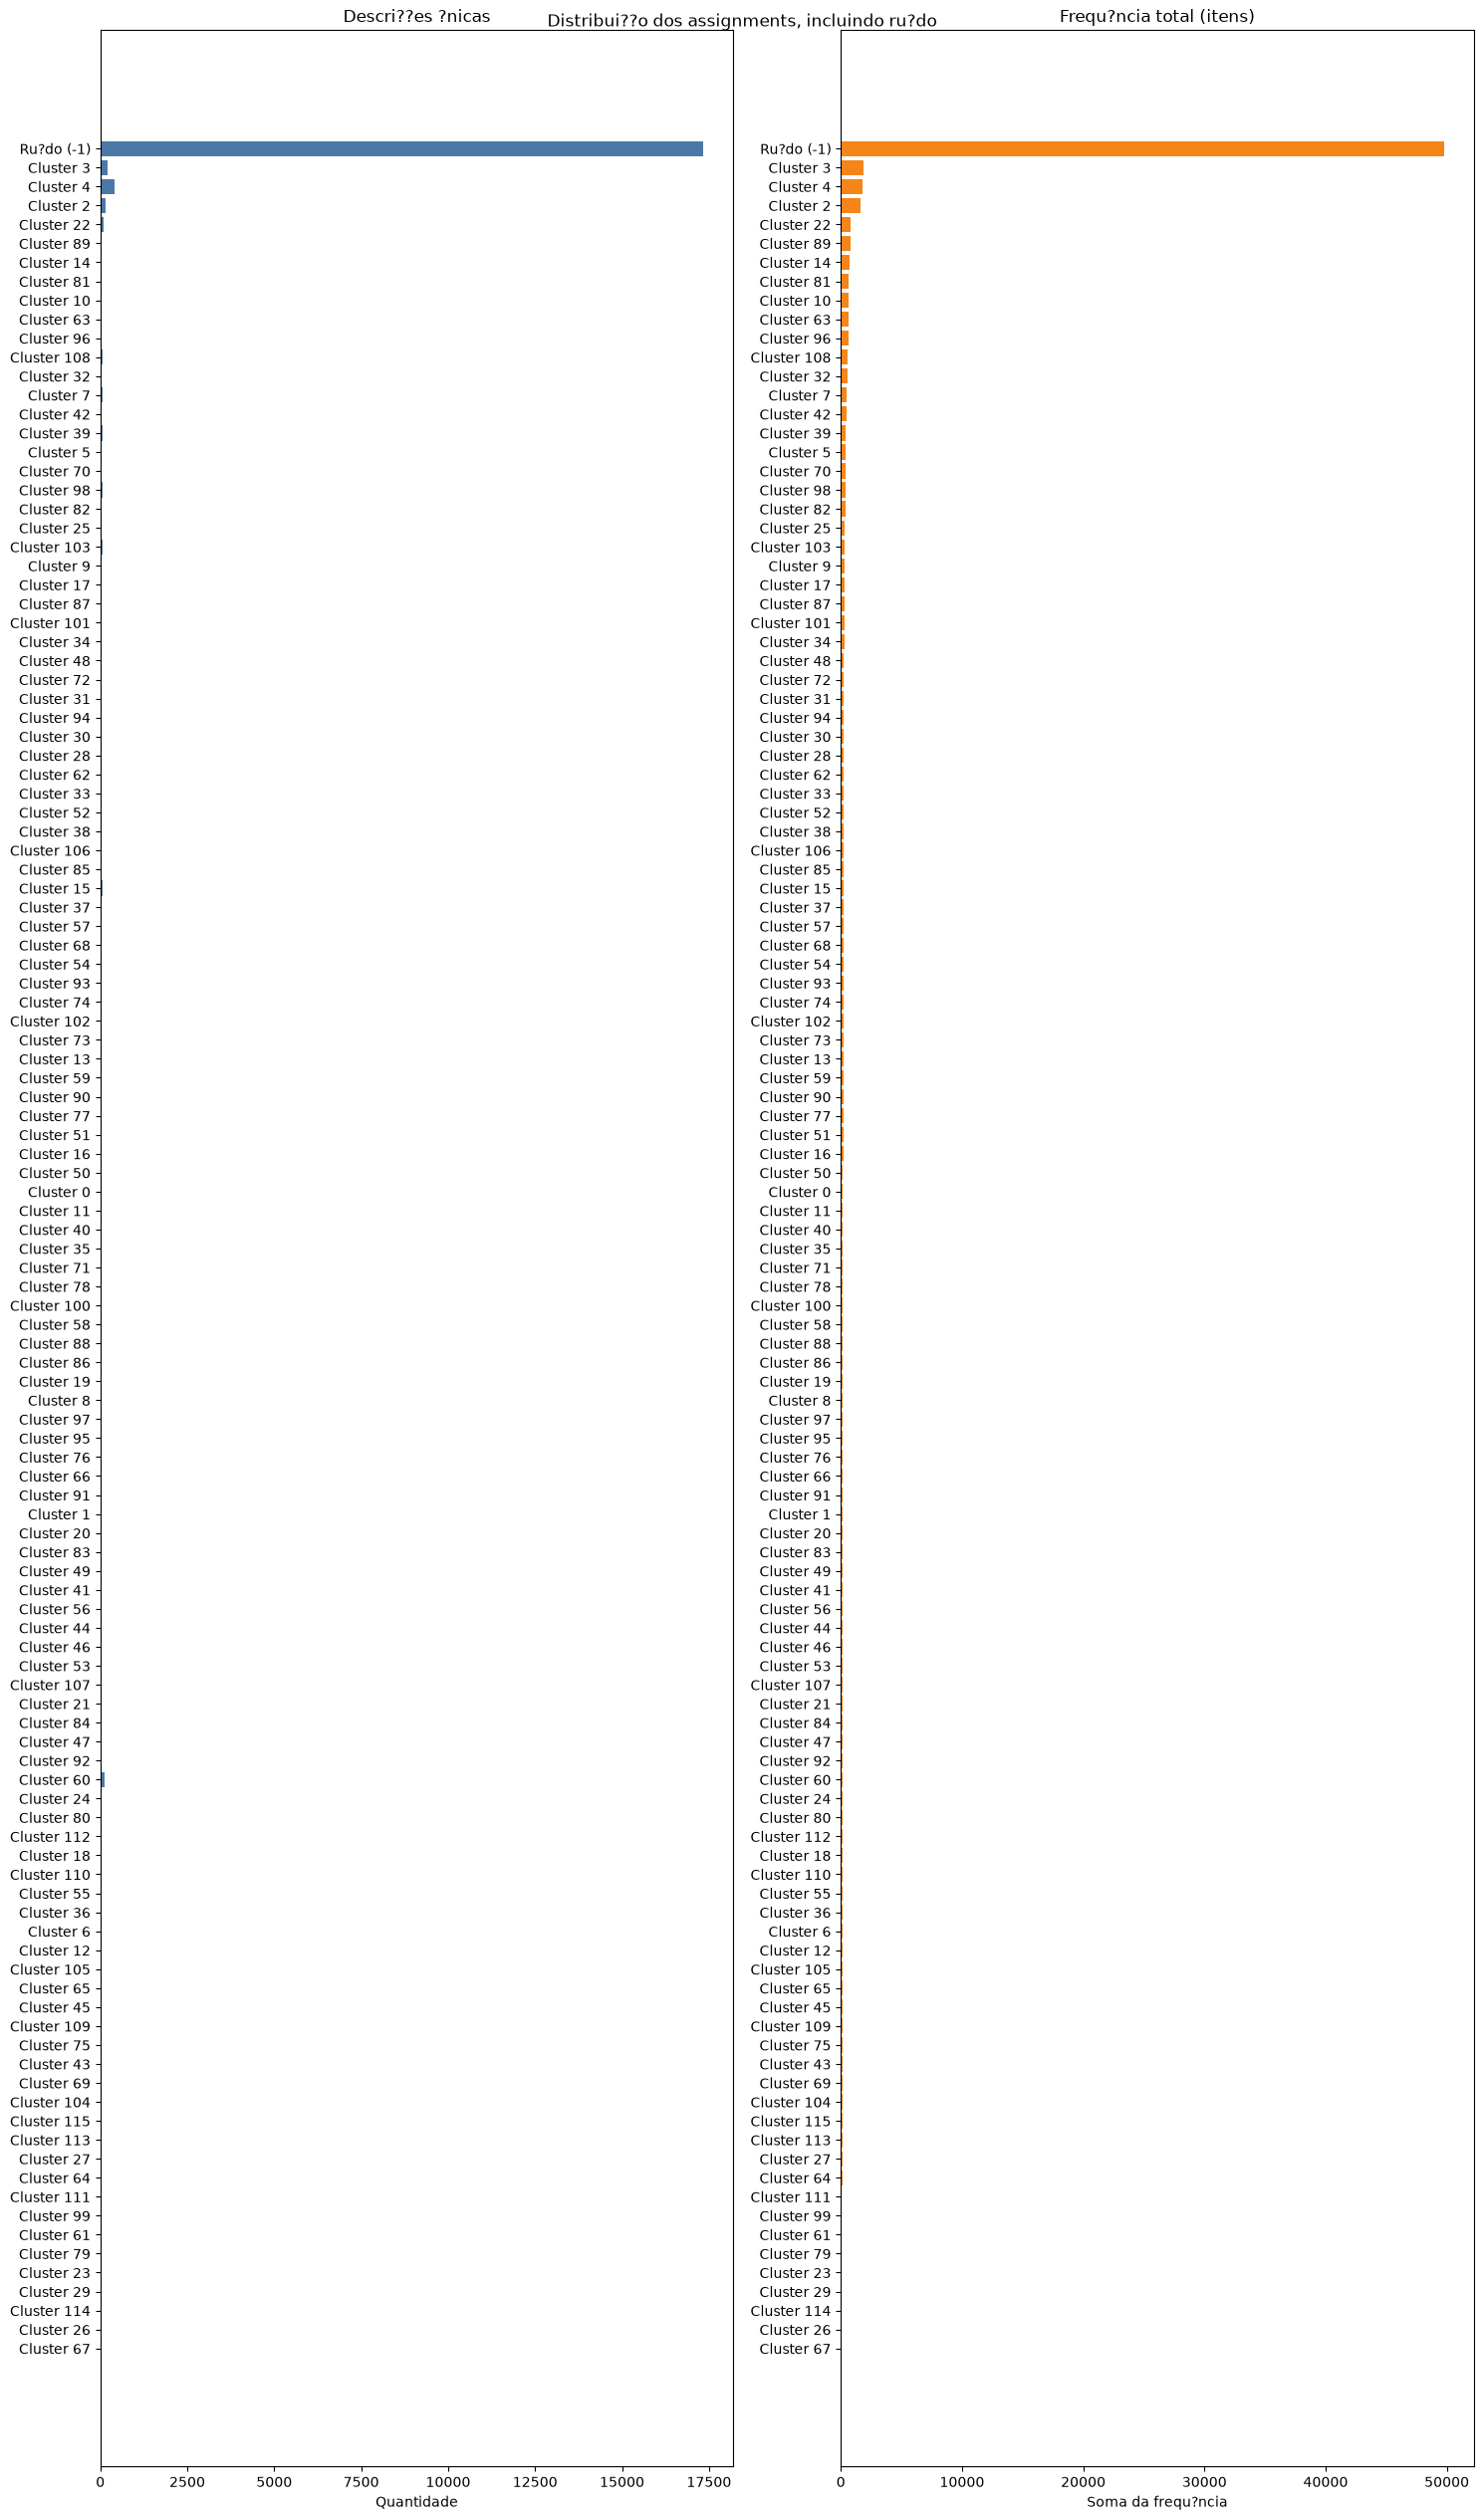

,cluster,descricoes_unicas,frequencia_total,participacao_descricoes_pct,participacao_frequencia_pct
5,4,422,1821,2.110,2.257737
4,3,197,1907,0.985,2.364362
3,2,162,1604,0.810,1.988693


In [12]:
plot_cluster_sizes(summary)

selected_summary = summary.loc[summary["cluster"].isin(CLUSTERS_TO_INSPECT)].copy()
selected_summary["cluster"] = pd.Categorical(selected_summary["cluster"], categories=CLUSTERS_TO_INSPECT, ordered=True)
selected_summary = selected_summary.sort_values("cluster")
display(selected_summary)


## 5. Exemplos mais frequentes

As descri??es abaixo ajudam a dar significado aos grupos. A frequ?ncia informa quantos itens agregados s?o representados por cada descri??o normalizada; exemplos frequentes n?o representam todas as varia??es do cluster.

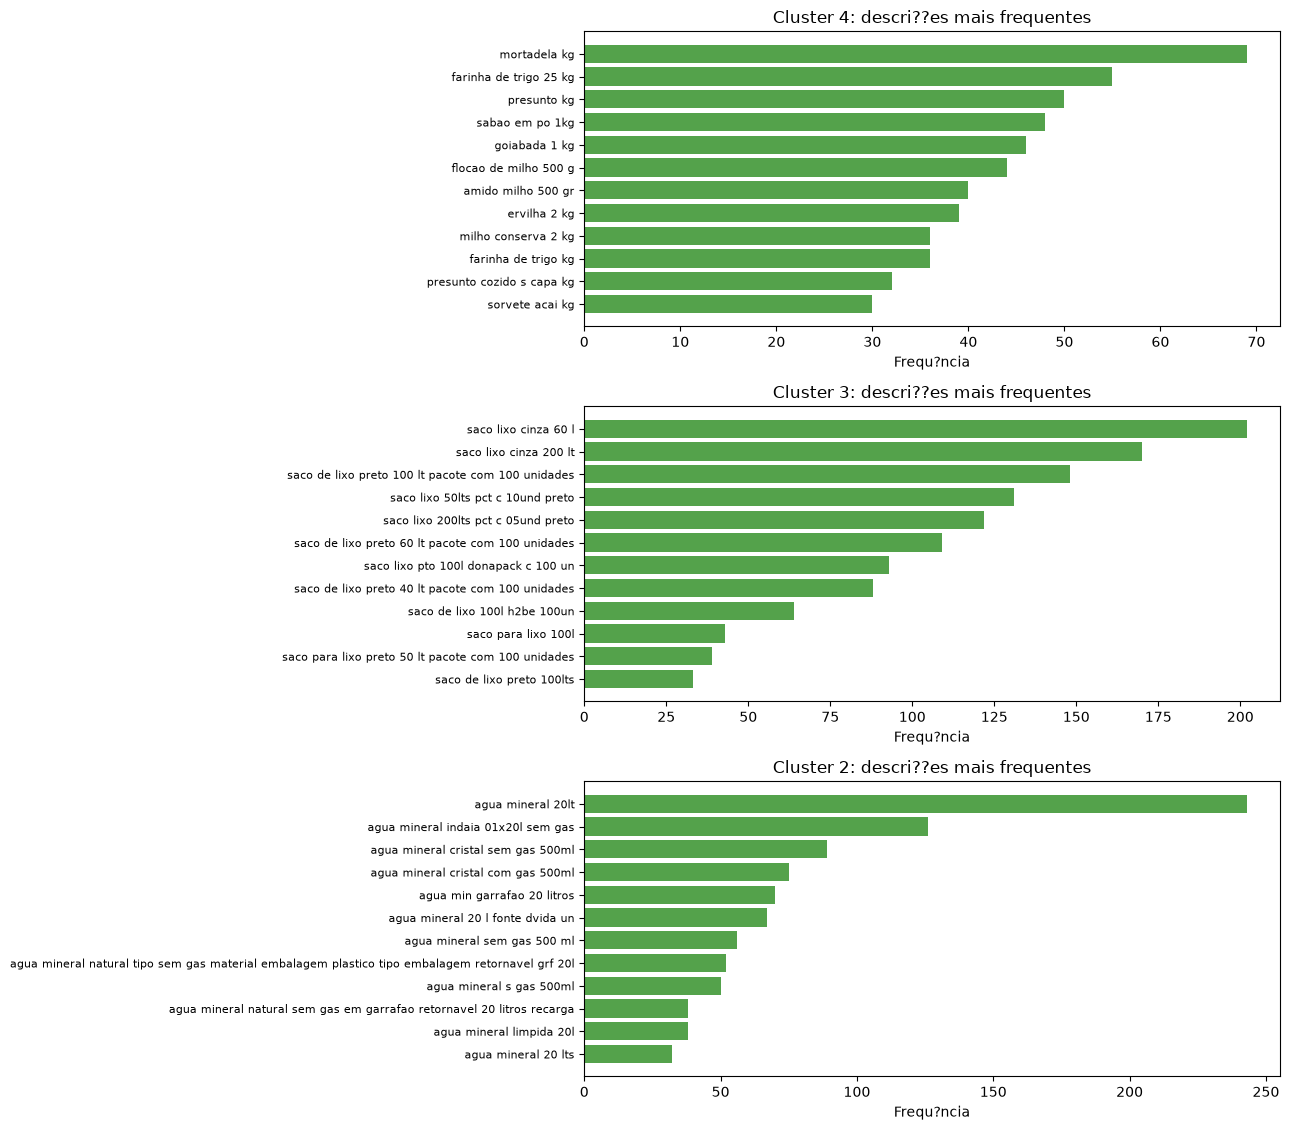

Cluster 4 ? descri??es de maior frequ?ncia


,descricao_normalizada,frequencia
0,mortadela kg,69
1,farinha de trigo 25 kg,55
2,presunto kg,50
3,sabao em po 1kg,48
4,goiabada 1 kg,46
5,flocao de milho 500 g,44
6,amido milho 500 gr,40
7,ervilha 2 kg,39
8,farinha de trigo kg,36
9,milho conserva 2 kg,36


Cluster 3 ? descri??es de maior frequ?ncia


,descricao_normalizada,frequencia
0,saco lixo cinza 60 l,202
1,saco lixo cinza 200 lt,170
2,saco de lixo preto 100 lt pacote com 100 unidades,148
3,saco lixo 50lts pct c 10und preto,131
4,saco lixo 200lts pct c 05und preto,122
5,saco de lixo preto 60 lt pacote com 100 unidades,109
6,saco lixo pto 100l donapack c 100 un,93
7,saco de lixo preto 40 lt pacote com 100 unidades,88
8,saco de lixo 100l h2be 100un,64
9,saco para lixo 100l,43


Cluster 2 ? descri??es de maior frequ?ncia


,descricao_normalizada,frequencia
0,agua mineral 20lt,243
1,agua mineral indaia 01x20l sem gas,126
2,agua mineral cristal sem gas 500ml,89
3,agua mineral cristal com gas 500ml,75
4,agua min garrafao 20 litros,70
5,agua mineral 20 l fonte dvida un,67
6,agua mineral sem gas 500 ml,56
7,agua mineral natural tipo sem gas material emb...,52
8,agua mineral s gas 500ml,50
9,agua mineral limpida 20l,38


In [13]:
plot_top_descriptions(assignments, CLUSTERS_TO_INSPECT, TOP_N_DESCRIPTIONS)
for cluster_id in CLUSTERS_TO_INSPECT:
    print(f"Cluster {cluster_id} ? descri??es de maior frequ?ncia")
    display(
        assignments.loc[assignments["cluster"] == cluster_id]
        .nlargest(TOP_N_DESCRIPTIONS, "frequencia")
        [["descricao_normalizada", "frequencia"]]
        .reset_index(drop=True)
    )


## 6. Termos distintivos e interpreta??o

O perfil lexical resume palavras associadas ?s descri??es do cluster, ponderadas pela frequ?ncia. O lift compara a participa??o do termo no cluster com sua participa??o nos outros clusters n?o ru?do; ? uma pista explorat?ria, n?o uma medida de qualidade nem uma valida??o sem?ntica. Leia os termos junto das descri??es completas.

In [14]:
for cluster_id in CLUSTERS_TO_INSPECT:
    profile = weighted_term_profile(assignments, cluster_id, TOP_N_TERMS)
    print(f"Cluster {cluster_id} ? termos com maior lift lexical")
    display(profile)


Cluster 4 ? termos com maior lift lexical


,termo,ocorrencias_ponderadas,lift_vs_outros_clusters
0,trigo,398.0,7.130061e+07
1,25kg,37.0,6.628450e+06
2,capa,32.0,5.732713e+06
3,1x25kg,27.0,4.836977e+06
4,peru,27.0,4.836977e+06
5,azedo,27.0,4.836977e+06
6,esp,26.0,4.657830e+06
7,calabresa,25.0,4.478682e+06
8,zanin,25.0,4.478682e+06
9,amafil,21.0,3.762093e+06


Cluster 3 ? termos com maior lift lexical


,termo,ocorrencias_ponderadas,lift_vs_outros_clusters
0,100l,272.0,3.342345e+07
1,10und,132.0,1.622020e+07
2,50lts,131.0,1.609732e+07
3,200lts,122.0,1.499140e+07
4,05und,122.0,1.499140e+07
5,donapack,94.0,1.155075e+07
6,h2be,64.0,7.864341e+06
7,100lts,44.0,5.406735e+06
8,fortlix,39.0,4.792333e+06
9,hospitalar,33.0,4.055051e+06


Cluster 2 ? termos com maior lift lexical


,termo,ocorrencias_ponderadas,lift_vs_outros_clusters
0,mineral,1477.0,1.883688e+08
1,gas,868.0,1.107002e+08
2,retornavel,151.0,1.925775e+07
3,01x20l,126.0,1.606938e+07
4,fonte,73.0,9.310038e+06
5,min,71.0,9.054968e+06
6,dvida,67.0,8.544829e+06
7,recarga,66.0,8.417295e+06
8,limpida,39.0,4.973856e+06
9,510ml,36.0,4.591252e+06


## 7. S?ntese da leitura

Use os exemplos, os termos e as frequ?ncias para atribuir um r?tulo provis?rio a cada grupo. A interpreta??o abaixo deve ser revisada ? luz das tabelas geradas:

- **Cluster 4:** mistura descri??es de alimentos e alguns produtos de limpeza. Isso sugere um agrupamento amplo ou rela??es textuais por atributos/formato, em vez de uma categoria de varejo ?nica.
- **Cluster 3:** descri??es de sacos para lixo, com varia??es de capacidade, cor, material e quantidade. O tema parece relativamente coeso e orientado ao tipo de produto.
- **Cluster 2:** descri??es de ?gua mineral, incluindo garraf?es retorn?veis e garrafas menores, com varia??es de marca e gaseifica??o. O agrupamento parece tem?tico, mas re?ne formatos diferentes.

Essas hip?teses s?o qualitativas e baseadas nas descri??es mais frequentes. DBSCAN foi ajustado sem NCM ou r?tulos humanos; a silhueta, a quantidade de ru?do e a inspe??o manual n?o provam que os grupos correspondam a categorias corretas. O cluster 4 merece aten??o especial porque re?ne itens aparentemente heterog?neos.

Para uma leitura espacial real do embedding, uma pr?xima execu??o precisaria salvar os embeddings (ou recalcul?-los com o mesmo modelo e os mesmos par?metros) antes de projet?-los em duas dimens?es. Uma proje??o deve sempre ser identificada como aproxima??o visual.